# Spherical-inclined validation vs pybhpt (independent implementation)

Per-mode cross-check of the batched 1D-q_theta integrator against the
committed pybhpt snapshot (`tests/golden/pybhpt_reference_v1.npz`), plus an
error-estimate audit and the (m, k) conjugate symmetry. All gates asserted.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hblteuk.geo import MiniGeo
from hblteuk.jax import solve_spherical_mode_table, flux_modes

ref = np.load("../tests/golden/pybhpt_reference_v1.npz")
t = ref["sph_table"]
l, m, k = (t[:, i].astype(int) for i in (0, 1, 2))
zin = t[:, 5] + 1j * t[:, 6]
zup = t[:, 7] + 1j * t[:, 8]
orbit = MiniGeo(*ref["sph_params"])
sol = solve_spherical_mode_table(orbit, -2, l, m, k)
amps = np.asarray(sol.amplitudes)

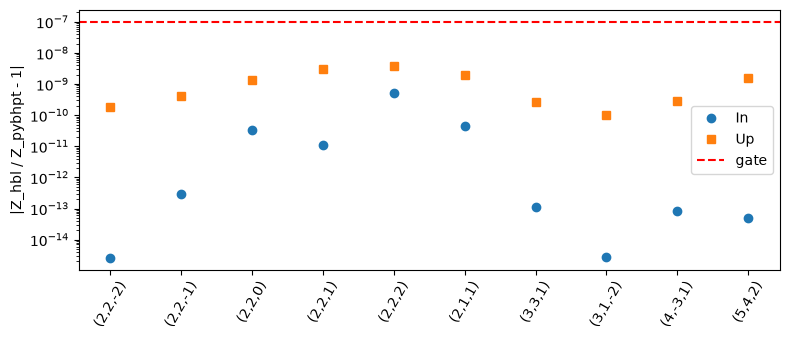

worst: In 5.15e-10, Up 3.85e-09


In [2]:
rel_in = np.abs(amps[:, 0] / zin - 1)
rel_up = np.abs(amps[:, 1] / zup - 1)
labels = [f"({a},{b},{c})" for a, b, c in zip(l, m, k)]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(rel_in, "o", label="In"); ax.semilogy(rel_up, "s", label="Up")
ax.set_xticks(range(len(labels)), labels, rotation=60)
ax.axhline(1e-7, color="r", ls="--", label="gate")
ax.set_ylabel("|Z_hbl / Z_pybhpt - 1|"); ax.legend()
plt.tight_layout(); plt.show()
print(f"worst: In {rel_in.max():.2e}, Up {rel_up.max():.2e}")
assert rel_in.max() < 1e-7 and rel_up.max() < 1e-7

In [3]:
fx = flux_modes(sol.amplitudes, sol.m, sol.omega, sol.eigenvalues, orbit.a)
Edot, Ldot = np.asarray(fx.Edot), np.asarray(fx.Ldot)
for col, ours, name in [(9, Edot[:, 0], "Edot_inf"), (10, Edot[:, 1], "Edot_hor"),
                        (11, Ldot[:, 0], "Ldot_inf"), (12, Ldot[:, 1], "Ldot_hor")]:
    rel = np.max(np.abs(ours / t[:, col] - 1))
    print(f"{name}: max rel diff {rel:.2e}")
    assert rel < 1e-7
print(f"superradiant (Edot_hor < 0) modes in table: {(Edot[:, 1] < 0).sum()}")

Edot_inf: max rel diff 7.43e-09
Edot_hor: max rel diff 3.42e-10
Ldot_inf: max rel diff 7.43e-09
Ldot_hor: max rel diff 3.42e-10
superradiant (Edot_hor < 0) modes in table: 9


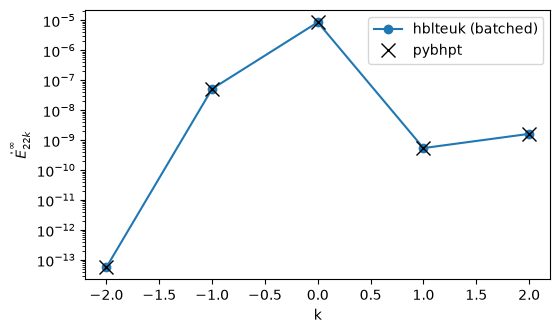

In [4]:
sel = (l == 2) & (m == 2)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(k[sel], Edot[sel, 0], "o-", label="hblteuk (batched)")
ax.semilogy(k[sel], t[sel, 9], "kx", ms=10, label="pybhpt")
ax.set_xlabel("k"); ax.set_ylabel(r"$\dot{E}^\infty_{22k}$"); ax.legend()
plt.show()

In [5]:
fine = np.asarray(sol.amplitudes)
for ns in (2**4, 2**5, 2**6):
    c = solve_spherical_mode_table(orbit, -2, l, m, k, nsamples=ns)
    actual = np.abs(np.asarray(c.amplitudes) / fine - 1)
    est = np.asarray(c.errors)
    selng = actual > 1e-12
    if not selng.any():
        # |k| <= 2 modes converge spectrally even on the coarsest grids;
        # nothing above the noise floor means nothing to underestimate
        print(f"nsamples = {ns}: all modes converged below 1e-12")
        continue
    ratio = est[selng] / actual[selng]
    print(f"nsamples = {ns}: min(est/actual) = {ratio.min():.2e}")
    assert np.all(ratio > 1e-2)   # never a dangerous underestimate

nsamples = 16: min(est/actual) = 1.42e+08


nsamples = 32: all modes converged below 1e-12


nsamples = 64: all modes converged below 1e-12


In [6]:
sol2 = solve_spherical_mode_table(orbit, -2, l, -m, -k)
a2 = np.asarray(sol2.amplitudes)
rel = np.max(np.abs(a2 / ((-1.0)**(l + k))[:, None] / np.conj(amps) - 1))
print(f"Z(l,-m,-k) vs (-1)^(l+k) conj(Z): max rel diff {rel:.2e}")
assert rel < 1e-7

Z(l,-m,-k) vs (-1)^(l+k) conj(Z): max rel diff 9.47e-13
